# BBC News Classification with BERT: Lab
# Solution

## Overview
As a junior data scientist at NewsInsight, a media analytics company, you've been tasked with building an automated news categorization system. Your team needs to classify incoming news articles into appropriate categories to help journalists, researchers, and business analysts quickly find relevant information.

The company receives thousands of articles daily from various sources. Currently, human editors spend significant time manually categorizing these articles, which is time-consuming and inconsistent. Your manager has asked you to develop a machine learning solution that can automatically categorize news articles into predefined categories (business, entertainment, politics, sport, tech).

This project will follow the BERT fine-tuning process you've learned:
1. Understanding data and defining requirements
2. Selecting and preparing the BERT model
3. Data preparation and tokenization
4. Model architecture design
5. Fine-tuning the model
6. Evaluation and refinement

Successfully implementing this system will significantly improve workflow efficiency, allowing editors to focus on content quality rather than manual categorization.

## Part 1: Environment Setup and Data Loading

In [10]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import seaborn as sns

# Set random seeds for reproducibility
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed()

In [11]:
# Load the data from csv file
df = pd.read_csv('bbc_news_data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


## Part 2: Data Exploration and Preprocessing

Explore the dataset, displaying basic information and:
- Analyze category distribution
- Check text length distribution
- Train test split data, use 75-25 split

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...
5,business,006.txt,Japan narrowly escapes recession,Japan's economy teetered on the brink of a te...
6,business,007.txt,Jobs growth still slow in the US,The US created fewer jobs than expected in Ja...
7,business,008.txt,India calls for fair trade rules,"India, which attends the G7 meeting of seven ..."
8,business,009.txt,Ethiopia's crop production up 24%,Ethiopia produced 14.27 million tonnes of cro...
9,business,010.txt,Court rejects $280bn tobacco case,A US government claim accusing the country's ...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


,category,filename,title,content
count,2225,2225,2225,2225
unique,5,511,2096,2092
top,sport,386.txt,Economy 'strong' in election year,Music and film fans will be able to control t...
freq,511,5,2,2


/tmp/ipykernel_1270/1817188779.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values, ax=ax[0], palette='viridis')


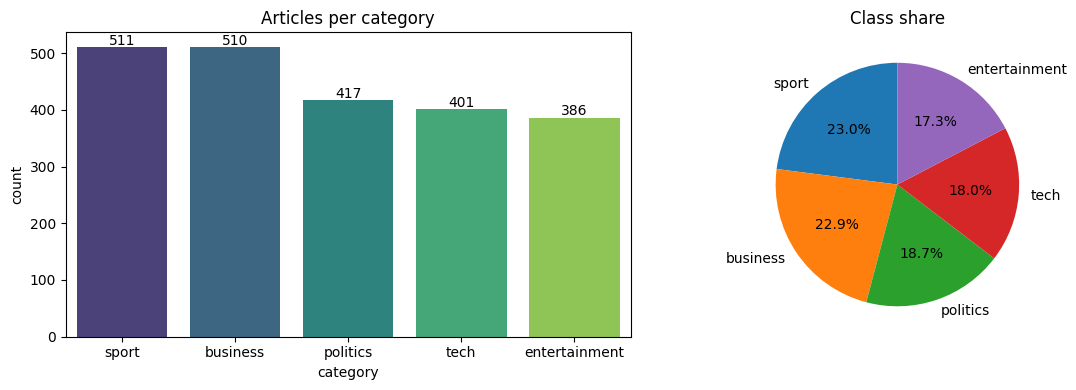

Average text length: 2232.793258426966
Min text length: 471
Max text length: 25454


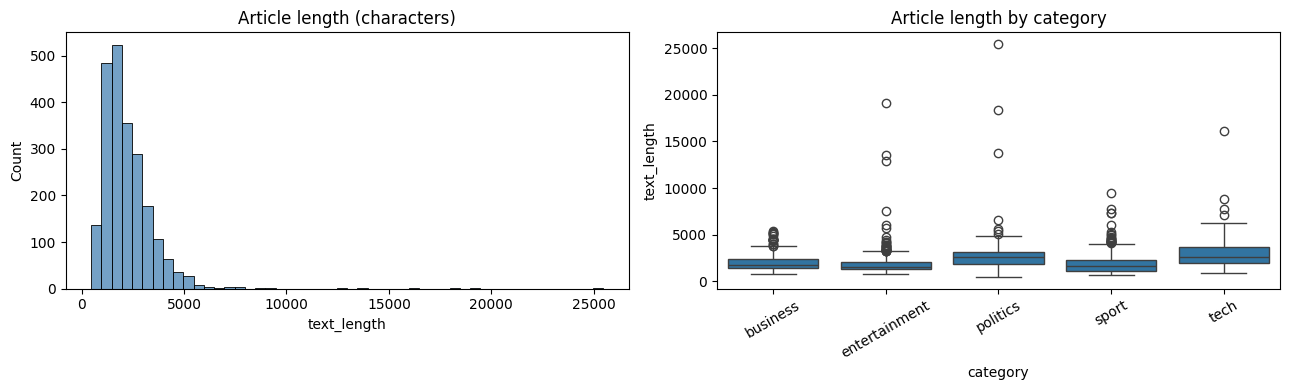

Missing values per column
category       0
filename       0
title          0
content        0
text_length    0
dtype: int64
Training set size: 1334
Validation set size: 334
Test set size: 557

Category distribution in training set:
category
business         306
sport            306
politics         250
tech             241
entertainment    231
Name: count, dtype: int64

Category distribution in validation set:
category
sport            77
business         76
politics         63
tech             60
entertainment    58
Name: count, dtype: int64

Category distribution in test set:
category
business         128
sport            128
politics         104
tech             100
entertainment     97
Name: count, dtype: int64


In [12]:
# Explore the first 10 rows
display(df.head(10))

# Basic info and describe
df.info()
display(df.describe(include='all'))

# Category distribution
category_counts = df['category'].value_counts()
category_counts

# Visualize category distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=category_counts.index, y=category_counts.values, ax=ax[0], palette='viridis')
ax[0].set_title('Articles per category'); ax[0].set_ylabel('count')
for i, v in enumerate(category_counts.values):
    ax[0].text(i, v + 4, str(v), ha='center')
ax[1].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%', startangle=90)
ax[1].set_title('Class share')
plt.tight_layout(); plt.show()

# Text length analysis
df['text_length'] = df['content'].str.len()
print(f"Average text length: {df['text_length'].mean()}")
print(f"Min text length: {df['text_length'].min()}")
print(f"Max text length: {df['text_length'].max()}")

# Visualize text length by category
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['text_length'], bins=50, ax=ax[0], color='steelblue')
ax[0].set_title('Article length (characters)')
sns.boxplot(data=df, x='category', y='text_length', ax=ax[1])
ax[1].set_title('Article length by category'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

# Check for missing values
print("Missing values per column")
print(df.isnull().sum())

# Map category labels to integers for classification
categories = list(df['category'].unique())
category_mapping = {category: i for i, category in enumerate(categories)}
df['label'] = df['category'].map(category_mapping)

# Rename content column into text for hugging face
df.rename(columns={'content': 'text'}, inplace=True)

# Split into train, validation, and test sets, make sure to stratify based on category, keep features and target together for now
# First, create train+validation and test sets
train_val_df, test_df = train_test_split(df, test_size=0.25, stratify=df['category'], random_state=42)
# Then split train+validation into separate train and validation sets
train_df, val_df = train_test_split(train_val_df, test_size=0.2, stratify=train_val_df['category'], random_state=42)

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Ensure categories are distributed properly across splits
print("\nCategory distribution in training set:")
print(train_df['category'].value_counts())
print("\nCategory distribution in validation set:")
print(val_df['category'].value_counts())
print("\nCategory distribution in test set:")
print(test_df['category'].value_counts())

## Part 3: Choose Your Model Approach
You can implement either the TensorFlow approach OR the Hugging Face approach. Delete the one you do not use.

### ------ TensorFlow Approach --------
Implement BERT with TensorFlow and TensorFlow Hub
- Import required libraries
- Select and load a BERT model
- Create datasets
 - Build model architecture
 - Fine-tune the model
 - Evaluate performance
 - Create visuals for train and validation data metrics across epochs

In [13]:
# Make sure to set legacy Keras to work with TF Hub BERT before you import
os.environ['TF_USE_LEGACY_KERAS']= '1'

# Import TensorFlow-specific libraries
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text as text

# Select and load BERT model
bert_model_name = 'small_bert/bert_en_uncased_L-4_H-512_A-8'

map_name_to_handle = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-512_A-8/1'
}

map_model_to_preprocess = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3'
}

tfhub_handle_encoder = map_name_to_handle[bert_model_name]
tfhub_handle_preprocess = map_model_to_preprocess[bert_model_name]

# Create TensorFlow datasets
def create_tf_dataset(texts, labels, batch_size=32, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((texts.tolist(), labels.values))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(texts), seed=42)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Convert pandas DataFrames to TensorFlow datasets
train_dataset = create_tf_dataset(train_df['text'], train_df['label'])
val_dataset = create_tf_dataset(val_df['text'], val_df['label'], shuffle=False)
# Make sure to not shuffle for test data
test_dataset = create_tf_dataset(test_df['text'], test_df['label'], shuffle=False)

# Build the BERT model
def build_tf_classifier_model():
    # Text input
    text_input = tf.keras.layers.Input(shape=(), dtype=tf.string, name='text')

    # Preprocessing layer
    preprocessing_layer = hub.KerasLayer(tfhub_handle_preprocess, name='preprocessing')
    encoder_inputs = preprocessing_layer(text_input)

    # BERT encoder - set trainable=True for fine-tuning
    encoder = hub.KerasLayer(tfhub_handle_encoder, trainable=True, name='BERT_encoder')
    outputs = encoder(encoder_inputs)

    # Use the pooled output for classification
    net = outputs['pooled_output']

    # Add dropout for regularization
    net = tf.keras.layers.Dropout(0.1)(net)

    # Add classification layer (for 5 categories)
    net = tf.keras.layers.Dense(5, activation=None, name='classifier')(net)

    # Create model
    model = tf.keras.Model(text_input, net)
    return model

# Create model
tf_classifier_model = build_tf_classifier_model()
tf_classifier_model.summary()

# Compile the model
# Using sparse categorical crossentropy since our labels are integers
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
# Select accuracy as metric
metrics = [tf.keras.metrics.SparseCategoricalAccuracy('accuracy')]

# Set up learning rate and optimizer
init_lr = .0005
optimizer = tf.keras.optimizers.Adam(learning_rate=init_lr)

# Compile the model
tf_classifier_model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

# Set up early stopping callback based on validation accuracy
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)


# Train the model for 5 epochs (not enough epochs most likely but to save on time)
print('Fine-tuning BERT model...')
history = tf_classifier_model.fit(train_dataset, validation_data=val_dataset, epochs=5, callbacks=[early_stopping])

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_type_ids': (None,    0         ['text[0][0]']                
                             128),                                                                
                              'input_mask': (None, 128)                                           
                             , 'input_word_ids': (None,                                           
                              128)}                                                               
                                                                                            

In [15]:
# Evaluate model on testing data
test_loss, test_accuracy = tf_classifier_model.evaluate(test_dataset)
print(f'Test accuracy (TensorFlow): {test_accuracy:.3f}')

18/18 [==============================] - 88s 5s/step - loss: 0.2031 - accuracy: 0.9551
Test accuracy (TensorFlow): 0.955


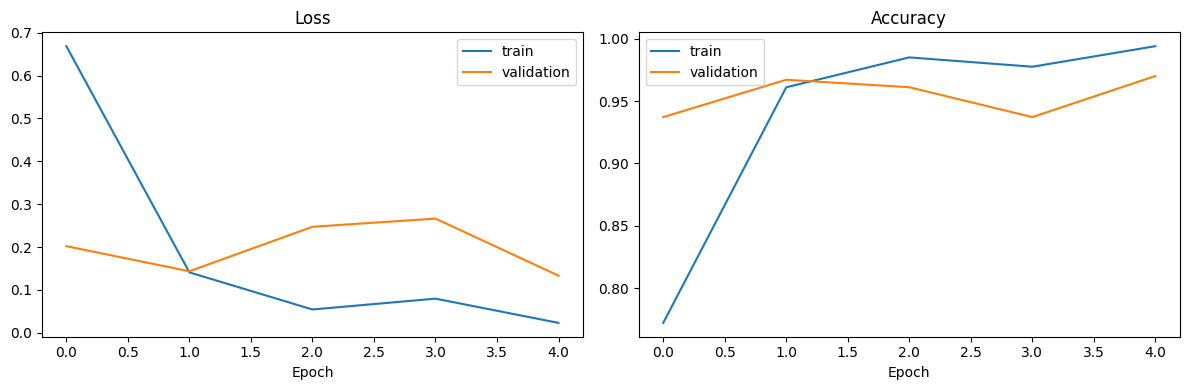

In [24]:
# Training curves (TensorFlow)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

### ------- Hugging Face Approach -------
Implement BERT with Hugging Face Transformers
- Import required libraries
- Select and load a BERT model
- Tokenize data
- Create datasets
- Fine-tune the model
- Evaluate performance

In [16]:
# Import Hugging Face libraries
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from datasets import Dataset
import torch

# Select and load tokenizer
model_name = 'bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_name)

# Convert pandas DataFrames to Hugging Face datasets
train_dataset_hf = Dataset.from_pandas(train_df)
val_dataset_hf = Dataset.from_pandas(val_df)
test_dataset_hf = Dataset.from_pandas(test_df)

# Tokenize function (use 128 for max length)
def tokenize_function(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=128)

# Tokenize datasets
tokenized_train = train_dataset_hf.map(tokenize_function, batched=True)
tokenized_val = val_dataset_hf.map(tokenize_function, batched=True)
tokenized_test = test_dataset_hf.map(tokenize_function, batched=True)

# Load pre-trained model with classification head
model_hf = BertForSequenceClassification.from_pretrained(model_name, num_labels=len(categories))
# Set BERT encoder layers to not train
for param in model_hf.bert.parameters():
    param.requires_grad = False

# Define metrics computation function the returns a dictionary of scores - include at least accuracy
def compute_metrics(pred):
    preds = np.argmax(pred.predictions, axis=-1)
    return {'accuracy': accuracy_score(pred.label_ids, preds)}

# Set up training arguments (train for 5 epochs - not enough to fully train but for sake of time. Set learning rate of 0.0005)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,
    learning_rate=0.0005,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    save_total_limit=2,
    report_to='none',
)

# Initialize Trainer - include an early stopping callback with patience of 3
trainer = Trainer(
    model=model_hf,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

# Train the model
print('Fine-tuning BERT model with Hugging Face...')
trainer.train()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1334 [00:00<?, ? examples/s]

Map:   0%|          | 0/334 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=420, training_loss=1.3045596168154763, metrics={'train_runtime': 4192.3001, 'train_samples_per_second': 1.591, 'train_steps_per_second': 0.1, 'total_flos': 438749502558720.0, 'train_loss': 1.3045596168154763, 'epoch': 5.0})

In [17]:
# Evaluate the model
results = trainer.evaluate(tokenized_test)
print(f"Hugging Face Model Results: {results}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
No log,1.212827,5,0.635548


Hugging Face Model Results: {'eval_loss': 1.2128268480300903, 'eval_accuracy': 0.6355475763016158}


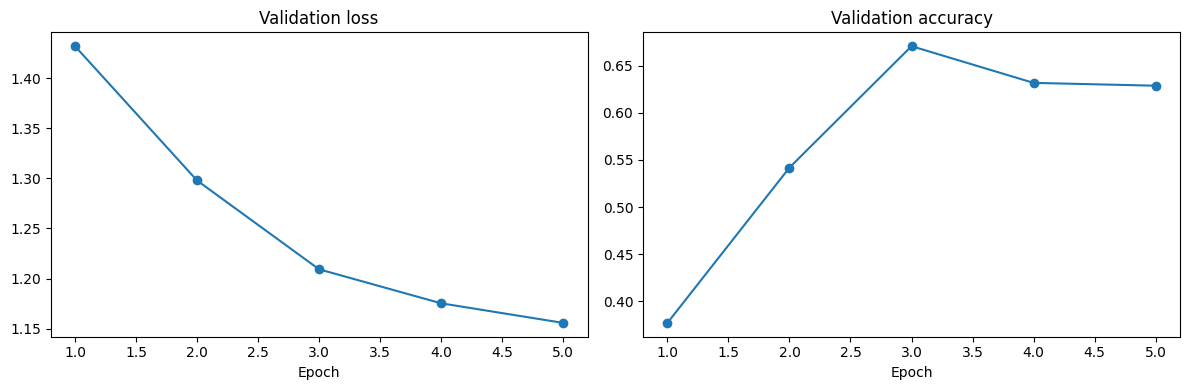

In [25]:
# Validation curves (Hugging Face)
log = pd.DataFrame(trainer.state.log_history)
ev = log[log['eval_loss'].notna()].drop_duplicates('epoch', keep='first')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ev['epoch'], ev['eval_loss'], 'o-'); ax[0].set_title('Validation loss'); ax[0].set_xlabel('Epoch')
ax[1].plot(ev['epoch'], ev['eval_accuracy'], 'o-'); ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()

## Part 4: Model Analysis and Inference
Analyze model performance on testing data
- Create confusion matrix visualization
- Analyze misclassifications
- Identify strengths and weaknesses

### Tensorflow Model

18/18 [==============================] - 87s 5s/step


<Figure size 1000x800 with 0 Axes>

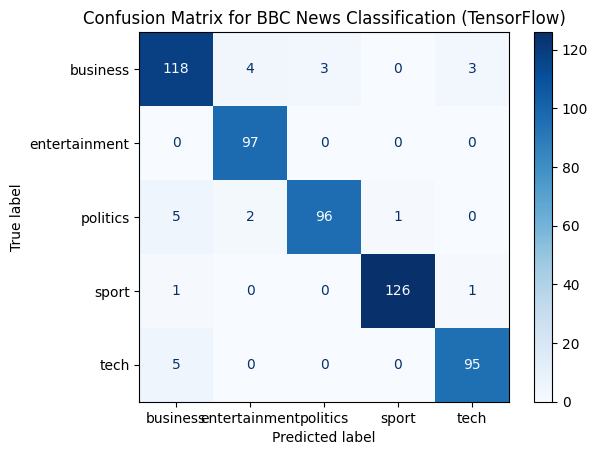


Classification Report:
               precision    recall  f1-score   support

     business       0.91      0.92      0.92       128
entertainment       0.94      1.00      0.97        97
     politics       0.97      0.92      0.95       104
        sport       0.99      0.98      0.99       128
         tech       0.96      0.95      0.95       100

     accuracy                           0.96       557
    macro avg       0.96      0.96      0.96       557
 weighted avg       0.96      0.96      0.96       557


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.9551
- Best performing category: sport

Weaknesses:
- Worst performing category: business


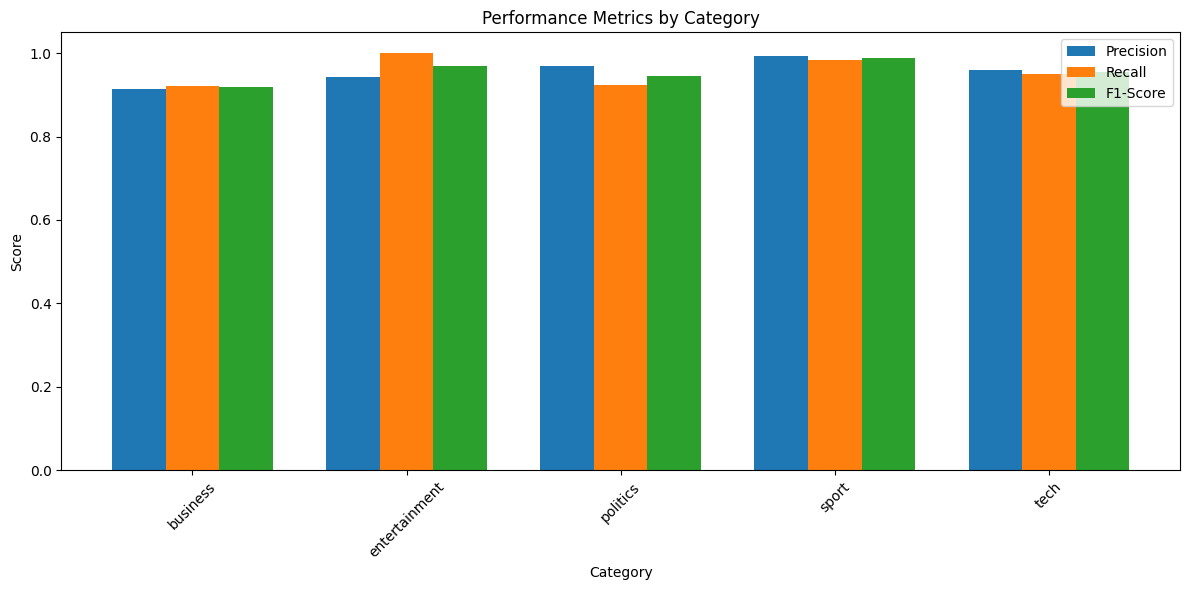

In [20]:
# Generate predictions for the test set
test_predictions = tf_classifier_model.predict(test_dataset)
y_pred = np.argmax(test_predictions, axis=1)

# Get true labels from testing data
y_true = [labels.numpy() for _, labels in test_dataset.unbatch()]

# Create and visualize the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (TensorFlow)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true, y_pred, target_names=categories, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))

# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics (use classification report)
per_class_metrics = {}
for cat in categories:
    per_class_metrics[cat] = report[cat]

# Find best and worst performing categories
best_category = max(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])
worst_category = min(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]}")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]}")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Create a function for model inference on new articles
def predict_article_category(text, model=tf_classifier_model):
    """
    Predict the category of a news article using the fine-tuned model.

    Args:
        text (str): The text of the news article
        model: The fine-tuned TensorFlow model

    Returns:
        dict: Prediction results including category and confidence scores
    """
    # Make prediction
    prediction = tf.nn.softmax(model.predict(tf.constant([text]), verbose=0)[0]).numpy()

    # Get the predicted category and confidence
    predicted_class_id = int(np.argmax(prediction))
    predicted_category = categories[predicted_class_id]
    confidence = float(prediction[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(prediction[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: tech (confidence: 0.9987)
All category confidences:
  - tech: 0.9987
  - business: 0.0011
  - entertainment: 0.0001
  - politics: 0.0000
  - sport: 0.0000

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: sport (confidence: 0.9998)
All category confidences:
  - sport: 0.9998
  - politics: 0.0001
  - entertainment: 0.0001
  - business: 0.0000
  - tech: 0.0000

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.9977)
All category confidences:
  - business: 0.9977
  - politics: 0.0013
  - entertainment: 0.0004
  - sport: 0.0003
  - tech: 0.0003

Sample 4:
Text: The new film starring the award-winning actress has

### Hugging Face Model

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


<Figure size 1000x800 with 0 Axes>

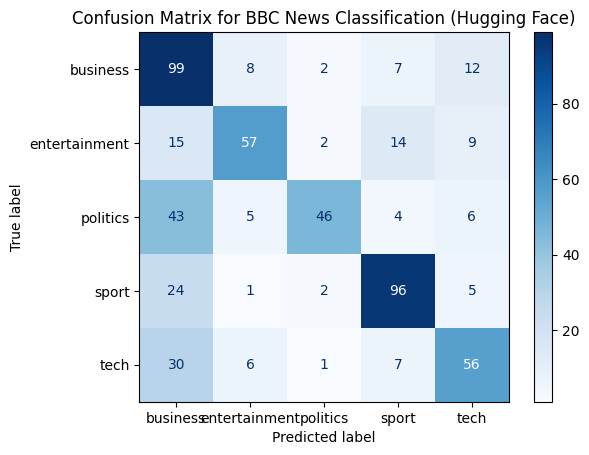


Classification Report:
               precision    recall  f1-score   support

     business       0.47      0.77      0.58       128
entertainment       0.74      0.59      0.66        97
     politics       0.87      0.44      0.59       104
        sport       0.75      0.75      0.75       128
         tech       0.64      0.56      0.60       100

     accuracy                           0.64       557
    macro avg       0.69      0.62      0.63       557
 weighted avg       0.69      0.64      0.64       557


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.6355
- Best performing category: sport

Weaknesses:
- Worst performing category: business


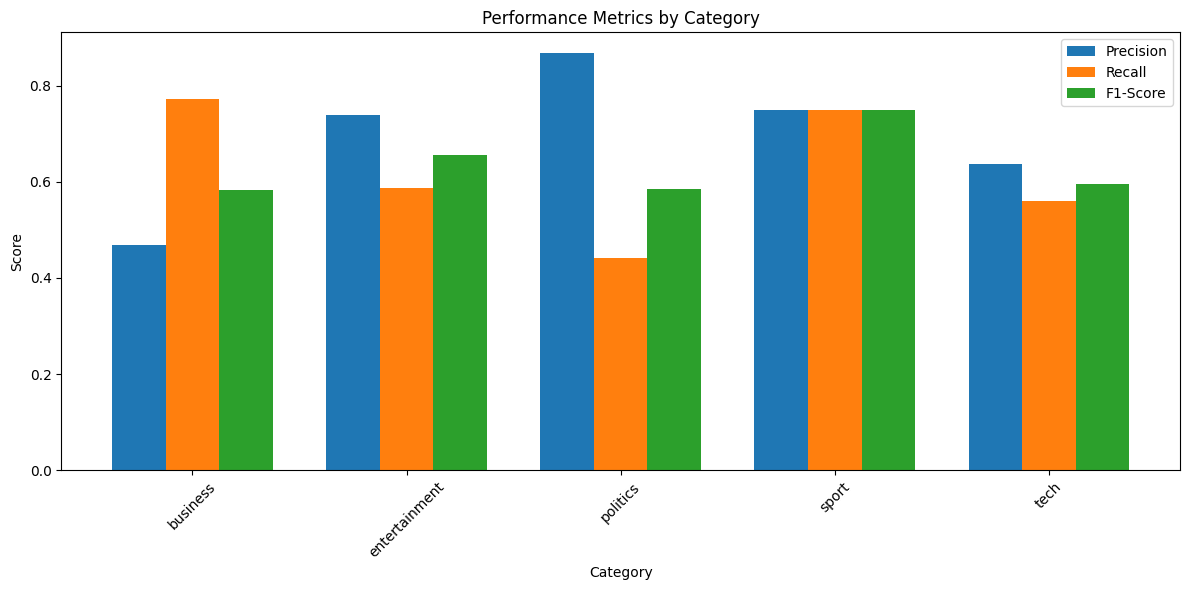

In [22]:
# Generate predictions for the test set
def get_predictions(trainer, dataset):
    # Run predictions with Hugging Face Trainer
    raw_predictions = trainer.predict(dataset)

    # Extract predictions and labels
    predictions = np.argmax(raw_predictions.predictions, axis=-1)
    labels = raw_predictions.label_ids

    return predictions, labels

y_pred, y_true = get_predictions(trainer, tokenized_test)

# Create and visualize the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (Hugging Face)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true, y_pred, target_names=categories, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))


# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics (use classification report)
per_class_metrics = {}
for cat in categories:
    per_class_metrics[cat] = report[cat]

# Find best and worst performing categories
best_category = max(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])
worst_category = min(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]}")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]}")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Create a function for model inference on new articles
def predict_article_category(text, model=model_hf, tokenizer=tokenizer):
    """
    Predict the category of a news article using the fine-tuned model.

    Args:
        text (str): The text of the news article
        model: The fine-tuned Hugging Face model
        tokenizer: The tokenizer for the model

    Returns:
        dict: Prediction results including category and confidence scores
    """
    # Tokenize inputs
    inputs = tokenizer(text, padding='max_length', truncation=True, max_length=128, return_tensors='pt').to(model.device)

    # Get predictions
    with torch.no_grad():
        outputs = model(**inputs)

    # Convert to numpy for easier handling
    probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()[0]

    # Get the predicted category and confidence
    predicted_class_id = int(np.argmax(probs))
    predicted_category = categories[predicted_class_id]
    confidence = float(probs[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(probs[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: business (confidence: 0.3773)
All category confidences:
  - business: 0.3773
  - entertainment: 0.1903
  - tech: 0.1812
  - politics: 0.1453
  - sport: 0.1059

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: sport (confidence: 0.3076)
All category confidences:
  - sport: 0.3076
  - entertainment: 0.2957
  - business: 0.1657
  - politics: 0.1417
  - tech: 0.0893

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.4868)
All category confidences:
  - business: 0.4868
  - politics: 0.2023
  - tech: 0.1555
  - entertainment: 0.1018
  - sport: 0.0537

Sample 4:
Text: The new film starring the award-winning actress

# Part 5: Conclusion and Discussion
Summarize your findings
- What was the final accuracy and other metrics?
- What categories were easiest/hardest to classify?
- What challenges did you encounter?
- How might you improve the model further?


# Part 5: Conclusion and Discussion

**Final results.** The TensorFlow model (Small BERT, fully fine-tuned) reached a test accuracy of **95.5%**, with weighted precision, recall and F1 of about **0.96**. Validation accuracy peaked at 96.7% in epoch 2 and reached 97.0% in epoch 5, while training accuracy rose to 99.4%. The Hugging Face model (`bert-base-uncased` with a frozen encoder) reached only **63.6%** test accuracy, with weighted F1 of **0.64** and macro F1 of **0.63**.

**Easiest and hardest categories.** In both models, **sport** was the easiest category (TensorFlow F1 = 0.99, Hugging Face F1 = 0.75), probably because sport articles use very distinctive vocabulary such as teams, matches and scores. **Business** was the hardest (TensorFlow F1 = 0.92, Hugging Face F1 = 0.58), likely because it overlaps with politics and tech. In the Hugging Face model, business had high recall (0.77) but low precision (0.47), so articles from other categories were often labelled business. Politics recall was only 0.44.

**Challenges.**
- The Hugging Face model trains only the small classification head (about 3,800 parameters) on top of a frozen BERT. The TensorFlow model updates all of its roughly 28.8 million parameters. This is the main reason for the large accuracy gap.
- The Hugging Face model's confidence was low (about 0.3 to 0.5 per prediction), and it classified only 3 of the 5 sample articles correctly. The TensorFlow model classified all 5 with confidence above 0.99.
- Validation loss in the TensorFlow run was unstable across epochs (0.20, 0.14, 0.25, 0.27, 0.13), which suggests that a learning rate of 0.0005 is high for fine-tuning the whole encoder.
- Training was slow because no GPU was available. The TensorFlow run took about 7 minutes per epoch and the Hugging Face run about 70 minutes in total.
- The dataset contains duplicate articles (2,092 unique texts out of 2,225). Duplicates can appear in both the training and test sets, so the test scores may be slightly optimistic.

**Possible improvements.**
- Unfreeze some or all of the BERT layers in the Hugging Face model and use a smaller learning rate such as 2e-5 to 5e-5.
- Remove duplicates before splitting the data.
- Use a longer maximum sequence length, because articles are much longer than 128 tokens.
- Train on a GPU with more epochs, and let early stopping choose the best checkpoint.
- Try a lower learning rate or a learning-rate schedule for the TensorFlow model to stabilise validation loss.
- Send low-confidence predictions to human editors.